In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import scienceplots
# plt.style.use(['science', 'ieee'])
plt.style.use('science')
# plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 16

In [3]:
df = pd.read_csv('benchmark_results.csv')
df.head()

,method_group,variant,resolution,vertices,time_minutes,error,iterations_per_sec,status
0,our_method,spatial-nn,full,200000,23.046802,2.13,1.09,success
1,our_method,spectral-nn,full,200000,23.046802,2.07,0.36,success
2,our_method,spectral-icp,full,200000,23.046802,2.10,0.21,success
3,our_method,spatial-nn,120k,120000,23.001409,2.15,1.08,success
4,our_method,spectral-nn,120k,120000,23.001409,2.10,0.66,success


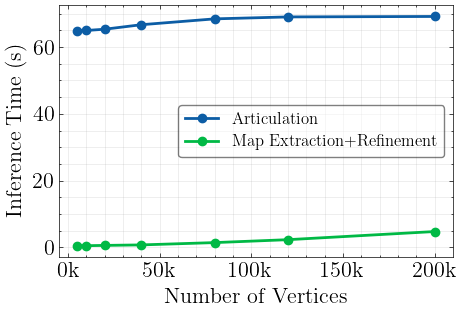

In [4]:
# Plot 1a: Inference Time vs Vertex Count
fig, ax = plt.subplots(figsize=(5, 3.5))

# Our method only (has time data)
our_data = df[df['method_group'] == 'our_method']
for variant in ['spectral-icp',]:
    variant_data = our_data[our_data['variant'] == variant].sort_values('vertices')
    ax.plot(variant_data['vertices'], variant_data['time_minutes'] / 20 * 60, 
            marker='o', label=f'Articulation', linewidth=2)

our_data = df[df['method_group'] == 'our_method']
for variant in ['spectral-icp',]:
    variant_data = our_data[our_data['variant'] == variant].sort_values('vertices')
    ax.plot(variant_data['vertices'], 1/variant_data['iterations_per_sec'], 
            marker='o', label=f'Map Extraction+Refinement', linewidth=2)

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x/1000)}k'))
ax.set_xlabel('Number of Vertices')
ax.set_ylabel('Inference Time (s)')
ax.legend(frameon=True, edgecolor='black', framealpha=0.5, fontsize=12, loc='best')
ax.grid(True, which='both', alpha=0.3, linestyle='-', linewidth=0.5)
plt.tight_layout()
plt.savefig('time_vs_vertices.pdf', dpi=300, bbox_inches='tight')
plt.show()

20000


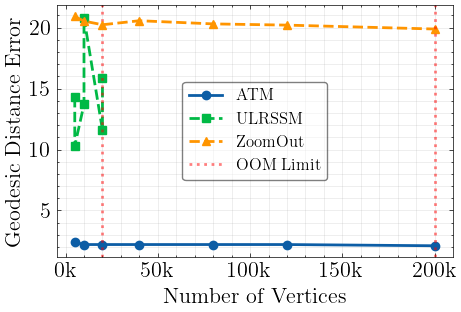

In [6]:
# Plot 2: Geodesic Error vs Vertex Count
fig, ax = plt.subplots(figsize=(5, 3.5))

# Our method
for variant in ['spectral-icp',]:
    variant_data = our_data[our_data['variant'] == variant].sort_values('vertices')
    ax.plot(variant_data['vertices'], variant_data['error'], 
            marker='o', label=f'ATM', linewidth=2)

# ULRSSM
ulrssm_data = df[(df['method_group'] == 'ulrssm') & (df['status'] == 'success')].sort_values('vertices')
ax.plot(ulrssm_data['vertices'], ulrssm_data['error'], 
        marker='s', label='ULRSSM', linewidth=2, linestyle='--')
# Mark OOM threshold
ulrssm_oom = df[(df['method_group'] == 'ulrssm') & (df['status'] == 'success')]['vertices'].max()
print(ulrssm_oom)
ax.axvline(ulrssm_oom, color='red', linestyle=':', alpha=0.5, linewidth=2)

# ZoomOut
for variant in ['spatial-init',]:
    zoom_data = df[(df['method_group'] == 'zoomout') & (df['variant'] == variant) & 
                   (df['status'] == 'success')].sort_values('vertices')
    ax.plot(zoom_data['vertices'], zoom_data['error'], 
            marker='^', label=f'ZoomOut', linewidth=2, linestyle='--')
# Mark OOM threshold
zoom_oom = df[(df['method_group'] == 'zoomout') & (df['status'] == 'success')]['vertices'].max()
ax.axvline(zoom_oom, color='red', linestyle=':', alpha=0.5, label='OOM Limit', linewidth=2)

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x/1000)}k'))
ax.set_xlabel('Number of Vertices')
ax.set_ylabel('Geodesic Distance Error')
# ax.set_title('Geodesic Error vs Mesh Resolution')
ax.legend(frameon=True, edgecolor='black', framealpha=0.5, fontsize=12, loc='best')
ax.grid(True, which='both', alpha=0.3, linestyle='-', linewidth=0.5)
plt.tight_layout()
plt.savefig('error_vs_vertices.pdf', dpi=300, bbox_inches='tight')
plt.show()